使用设备: cuda
参数量: 421,834
Epoch 01 | Train Loss 0.2387 Acc 92.77% | Test Loss 0.0449 Acc 98.55%
Epoch 02 | Train Loss 0.1098 Acc 96.81% | Test Loss 0.0590 Acc 98.08%
Epoch 03 | Train Loss 0.0883 Acc 97.33% | Test Loss 0.0409 Acc 98.67%
Epoch 04 | Train Loss 0.0745 Acc 97.71% | Test Loss 0.0346 Acc 98.85%
Epoch 05 | Train Loss 0.0653 Acc 97.94% | Test Loss 0.0332 Acc 98.99%
模型已保存为 mnist_cnn.pth


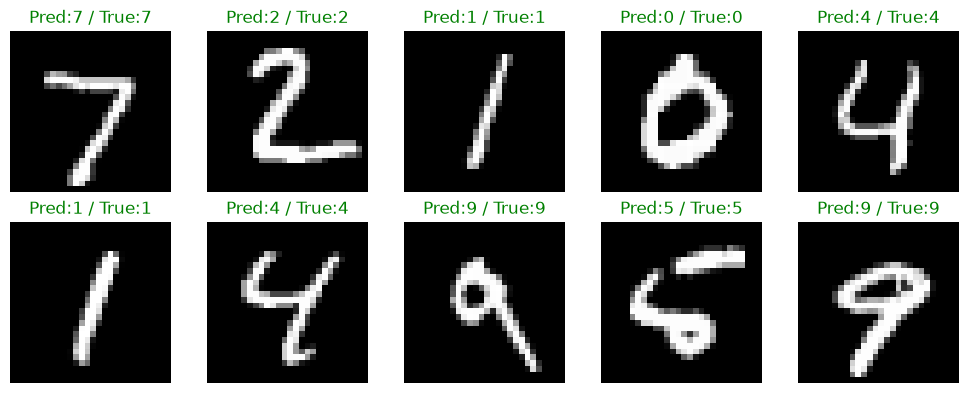

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# ============ 1. 配置 ============
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用设备: {device}")

BATCH_SIZE = 64
EPOCHS = 5
LR = 1e-3

# ============ 2. 数据准备 ============
transform = transforms.Compose([
    transforms.ToTensor(),                      # [0,255] -> [0,1], shape (1,28,28)
    transforms.Normalize((0.1307,), (0.3081,))  # MNIST 全局均值/标准差
])

train_dataset = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

# ============ 3. 模型定义 ============
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),  # (1,28,28) -> (32,28,28)
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),                 # -> (32,14,14)
            nn.Conv2d(32, 64, 3, padding=1), # -> (64,14,14)
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),                 # -> (64,7,7)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = CNN().to(device)
print(f"参数量: {sum(p.numel() for p in model.parameters()):,}")

# ============ 4. 损失与优化器 ============
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

# ============ 5. 训练与评估函数 ============
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += x.size(0)
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += x.size(0)
    return total_loss / total, correct / total

# ============ 6. 训练主循环 ============
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, criterion)
    te_loss, te_acc = evaluate(model, test_loader, criterion)
    print(f"Epoch {epoch:02d} | "
          f"Train Loss {tr_loss:.4f} Acc {tr_acc*100:.2f}% | "
          f"Test Loss {te_loss:.4f} Acc {te_acc*100:.2f}%")

# ============ 7. 保存模型 ============
torch.save(model.state_dict(), "mnist_cnn.pth")
print("模型已保存为 mnist_cnn.pth")

# ============ 8. 可视化预测结果 ============
model.eval()
images, labels = next(iter(test_loader))
with torch.no_grad():
    preds = model(images.to(device)).argmax(1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    img = images[i].squeeze()
    # 反归一化用于显示
    img = img * 0.3081 + 0.1307
    ax.imshow(img, cmap="gray")
    color = "green" if preds[i] == labels[i] else "red"
    ax.set_title(f"Pred:{preds[i].item()} / True:{labels[i].item()}", color=color)
    ax.axis("off")
plt.tight_layout()
plt.savefig("predictions.png", dpi=120)
plt.show()

In [2]:
!pip install matplotlib

  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 186.4 kB/s eta 0:00:48
   -- ------------------------------------- 0.5/9.3 MB 186.4 kB/s eta 0:00:48
   -- ------------------------------------- 0.5/9.3 MB 186.4 kB/s eta 0:00:48
   ---